# Import libraries

In [178]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit

from scipy import stats
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.compose import ColumnTransformer

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold, RandomizedSearchCV

from category_encoders import TargetEncoder
from scipy.stats import randint
import random


In [179]:
# Set fixed seed
random.seed(42)
np.random.seed(42)


# Info and Descriptive Statistics

In [180]:
# Open csv
df = pd.read_csv('seattle_events_airbnb.csv')

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 215047 entries, 0 to 215046
Data columns (total 9 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   listing_id                  215047 non-null  int64  
 1   date                        215047 non-null  str    
 2   is_booked                   215047 non-null  int64  
 3   day_of_week                 215047 non-null  str    
 4   neighborhood                215047 non-null  str    
 5   price                       215047 non-null  float64
 6   global_event_count          215047 non-null  int64  
 7   total_daily_capacity        215047 non-null  float64
 8   capacity_weighted_distance  124866 non-null  float64
dtypes: float64(3), int64(3), str(3)
memory usage: 14.8 MB


In [181]:
# Fill NaNs
df['capacity_weighted_distance'] = df['capacity_weighted_distance'].fillna(9999.0)

# df.info()

In [182]:
# Calculate lead time from scraped date

# Update data type of 'date' column
df['date'] = pd.to_datetime(df['date'])

# Date data was scraped
scraped_date = pd.to_datetime('2026-06-15')

# Create column for lead time
df['lead_time'] = (df['date'] - scraped_date).dt.days

# df.info()

In [183]:
# Use is_weekend instead of day_of_week

# Check if the day is in the list and convert True/False to 1/0
df['is_weekend'] = df['day_of_week'].isin(['Saturday', 'Sunday']).astype(int)

In [184]:
# Descriptive statistics
df.describe()

,listing_id,date,is_booked,price,global_event_count,total_daily_capacity,capacity_weighted_distance,lead_time,is_weekend
count,2.150470e+05,215047,215047.000000,215047.000000,215047.000000,215047.000000,215047.000000,215047.000000,215047.000000
mean,8.270289e+17,2026-08-16 00:00:00,0.396583,349.725273,0.645161,18696.548387,4195.200139,62.000000,0.322581
min,6.606000e+03,2026-08-01 00:00:00,0.000000,10.180000,0.000000,0.000000,0.052130,47.000000,0.000000
25%,4.790801e+07,2026-08-08 00:00:00,0.000000,171.500000,0.000000,0.000000,2.937102,54.000000,0.000000
50%,9.327041e+17,2026-08-16 00:00:00,0.000000,280.740000,1.000000,17151.000000,5.962833,62.000000,0.000000
75%,1.444585e+18,2026-08-24 00:00:00,1.000000,422.240000,1.000000,17151.000000,9999.000000,70.000000,1.000000
max,1.707715e+18,2026-08-31 00:00:00,1.000000,25916.670000,2.000000,85891.000000,9999.000000,77.000000,1.000000
std,6.495004e+17,NaN,0.489189,465.971871,0.598299,24562.799606,4932.293161,8.944293,0.467465


In [185]:
# Calculate the 99th percentile and cap the values (Winsorization) to avoid data loss

# Calculate the price at the 99th percentile
price_99th = df['price'].quantile(0.99)
print(f"The 99th percentile price is: ${price_99th:.2f}")

# Cap the outliers (any price above the 99th percentile gets set to the 99th percentile value)
df['price'] = df['price'].clip(upper=price_99th)

# Verify the new maximum value
print(f"The new maximum price in the dataset is: ${df['price'].max():.2f}")

df.info()
df.describe()


The 99th percentile price is: $1478.00
The new maximum price in the dataset is: $1478.00
<class 'pandas.DataFrame'>
RangeIndex: 215047 entries, 0 to 215046
Data columns (total 11 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   listing_id                  215047 non-null  int64         
 1   date                        215047 non-null  datetime64[us]
 2   is_booked                   215047 non-null  int64         
 3   day_of_week                 215047 non-null  str           
 4   neighborhood                215047 non-null  str           
 5   price                       215047 non-null  float64       
 6   global_event_count          215047 non-null  int64         
 7   total_daily_capacity        215047 non-null  float64       
 8   capacity_weighted_distance  215047 non-null  float64       
 9   lead_time                   215047 non-null  int64         
 10  is_weekend                

,listing_id,date,is_booked,price,global_event_count,total_daily_capacity,capacity_weighted_distance,lead_time,is_weekend
count,2.150470e+05,215047,215047.000000,215047.000000,215047.000000,215047.000000,215047.000000,215047.000000,215047.000000
mean,8.270289e+17,2026-08-16 00:00:00,0.396583,336.086422,0.645161,18696.548387,4195.200139,62.000000,0.322581
min,6.606000e+03,2026-08-01 00:00:00,0.000000,10.180000,0.000000,0.000000,0.052130,47.000000,0.000000
25%,4.790801e+07,2026-08-08 00:00:00,0.000000,171.500000,0.000000,0.000000,2.937102,54.000000,0.000000
50%,9.327041e+17,2026-08-16 00:00:00,0.000000,280.740000,1.000000,17151.000000,5.962833,62.000000,0.000000
75%,1.444585e+18,2026-08-24 00:00:00,1.000000,422.240000,1.000000,17151.000000,9999.000000,70.000000,1.000000
max,1.707715e+18,2026-08-31 00:00:00,1.000000,1478.000000,2.000000,85891.000000,9999.000000,77.000000,1.000000
std,6.495004e+17,NaN,0.489189,246.608208,0.598299,24562.799606,4932.293161,8.944293,0.467465


# Univariate EDA

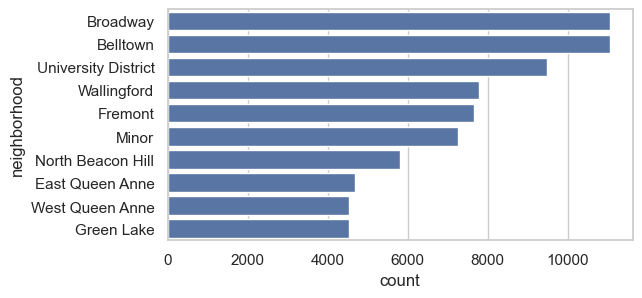

In [186]:
# Neighborhoods by listing volume

top_10_neighborhoods = df['neighborhood'].value_counts().head(10).reset_index()

plt.figure(figsize=(6, 3))

sns.barplot(
    data=top_10_neighborhoods,
    x='count',          
    y='neighborhood',   
)

plt.show()

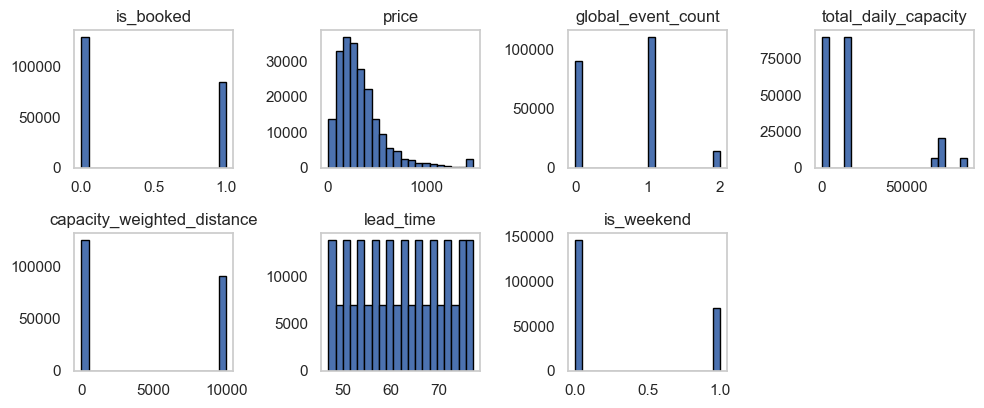

In [187]:
# Histogram grid

sns.set_theme(style="whitegrid")

# Plot features in grid
df.drop(columns=['listing_id', 'date']).hist(  # drop unnecessary features
    bins=20,
    figsize=(10, 6),
    layout=(3, 4),  # layout grid shape: 3 rows by 4 columns (adjust based on feature count)
    grid=False,
    edgecolor='black'
)

plt.tight_layout()

plt.show()


In [188]:
# Percent booked

count_booked = len(df[df['is_booked'] == 1])
count_available = len(df[df['is_booked'] == 0])

percent_booked = count_booked / (count_booked + count_available)
percent_available = count_available / (count_booked + count_available)

print(f"Percent booked: {(percent_booked * 100):.2f}%")
print(f"Percent available: {(percent_available * 100):.2f}%")

Percent booked: 39.66%
Percent available: 60.34%


# Multivariate EDA

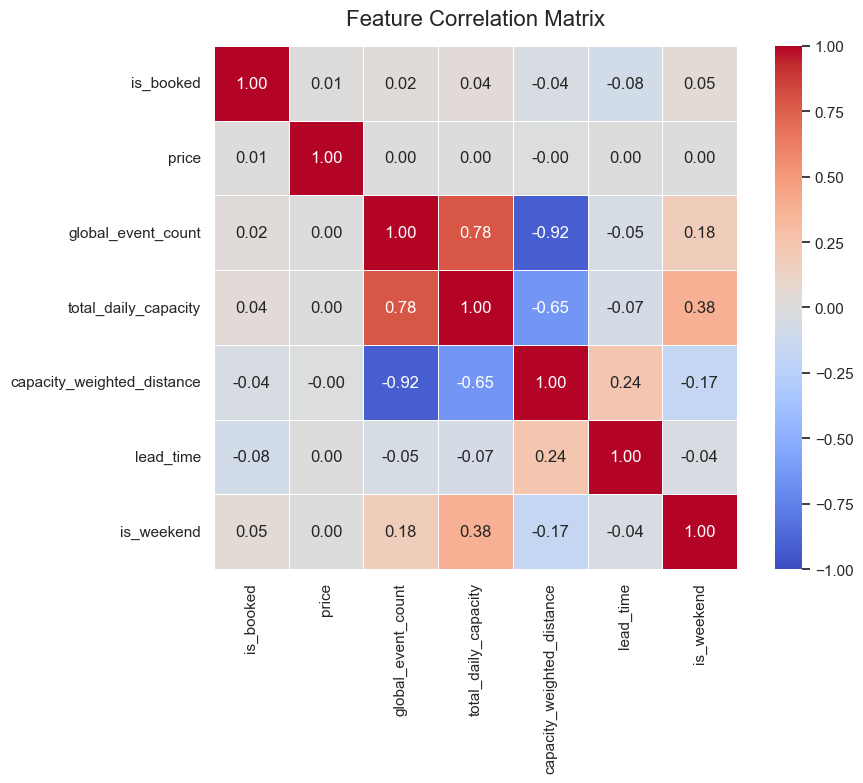

In [189]:
# Correlation matrix

corr_matrix = df.drop(columns=['listing_id']).corr(numeric_only=True)

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix, 
    annot=True,             # Show numeric correlation values inside the blocks
    fmt=".2f",              # Round numeric values to 2 decimal places
    cmap="coolwarm",        # Blue = Negative correlation, Red = Positive correlation
    vmin=-1, vmax=1,        # Set absolute min/max limits for the color bar scale
    linewidths=0.5,         # Add grid lines between the squares
    square=True             # Force grid blocks to be perfect squares
)

plt.title('Feature Correlation Matrix', fontsize=16, pad=15)
plt.tight_layout()
plt.show()


# Group split data by listing_id

In [190]:
# Initialize the group splitter
gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=42)

# Get the indices for the split based on the group
train_idx, test_idx = next(gss.split(df, groups=df['listing_id']))

# Create dataframes
train_df = df.iloc[train_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)



In [191]:
# Define features and target array
X_baseline = train_df.drop(columns=['listing_id', 'date', 'day_of_week', 'is_booked', 'global_event_count', 'total_daily_capacity', 'capacity_weighted_distance'])
X_enriched = train_df.drop(columns=['listing_id', 'date', 'day_of_week', 'is_booked'])
y = train_df['is_booked']
groups = train_df['listing_id']

# Build the column transformer
column_transformer = ColumnTransformer(
    transformers=[
        ('neighborhood', TargetEncoder(smoothing=10.0), ['neighborhood'])
    ],
    remainder='passthrough'
)

# Build the base pipeline
pipeline = Pipeline(
    steps=[
        ('column_transformer', column_transformer),
        ('classifier', RandomForestClassifier(
            random_state=42,                   
            n_jobs=-1,
            class_weight='balanced_subsample'
        ))
    ]
).set_output(transform='pandas')

# Initialize GroupKFold
group_kfold = GroupKFold(n_splits=5)

# Define distribution ranges for random sampling
param_distributions = {
    # Dynamically picks any integer from 5 up to 25
    'classifier__max_depth': randint(5, 26),
    # Dynamically picks any integer from 100 up to 500
    'classifier__n_estimators': randint(100, 501),

    # Hyperprams to control overfitting
    'classifier__min_samples_split': randint(2, 20),
    'classifier__min_samples_leaf': randint(1, 20),
    
    # Test different feature sub-selection strategies
    'classifier__max_features': [0.2, 0.4, 0.6, 0.8, 'sqrt', 'log2']
}

# Tuning Baseline Model via Random Search
print("Running Randomized Search on Baseline Model...")
random_search_baseline = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions,
    n_iter=5,                  # Evaluates 5 random combinations per model
    cv=group_kfold,            # Restricts cross-validation by listing groups
    scoring='roc_auc',         # Optimizes for Area Under the ROC Curve
    n_jobs=-1,                 # Uses all CPU cores
    random_state=42,           # Makes the random choices reproducible
    verbose=1
)
random_search_baseline.fit(X_baseline, y, groups=groups)

# Tuning Enriched Model via Random Search
print("\nRunning Randomized Search on Enriched Model...")
random_search_enriched = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions,
    n_iter=5,                  
    cv=group_kfold,            
    scoring='roc_auc',         
    n_jobs=-1,                 
    random_state=42,           
    verbose=1
)
random_search_enriched.fit(X_enriched, y, groups=groups)

# Print Best Hyperparams and Best Out-of-Fold Scores
print("\n=== OPTIMIZED RESULTS ===")
print(f"Baseline - Best Params: {random_search_baseline.best_params_}")
print(f"Baseline - Best CV ROC AUC: {random_search_baseline.best_score_:.4f}")

print(f"\nEnriched - Best Params: {random_search_enriched.best_params_}")
print(f"Enriched - Best CV ROC AUC: {random_search_enriched.best_score_:.4f}")


AUC_baseline = []
AUC_enriched = []

# Save best AUC scores for each fold
for i in range(5):
    AUC_baseline.append(random_search_baseline.cv_results_[f'split{i}_test_score'][random_search_baseline.best_index_])
    AUC_enriched.append(random_search_enriched.cv_results_[f'split{i}_test_score'][random_search_enriched.best_index_])

# Print the best AUC scores for each fold
#print(f"\nBaseline - AUC scores per fold: {AUC_baseline}")
#print(f"Enriched - AUC scores per fold: {AUC_enriched}")

# Print fold scores for a search object
def print_best_fold_scores(search_obj, name):
    best_idx = search_obj.best_index_
    print(f"\n{name} - Score per fold:")
    for i in range(5):
        score = search_obj.cv_results_[f'split{i}_test_score'][best_idx]
        print(f"  Fold {i+1}: {score:.4f}")

print_best_fold_scores(random_search_baseline, "Baseline")
print_best_fold_scores(random_search_enriched, "Enriched")



Running Randomized Search on Baseline Model...
Fitting 5 folds for each of 5 candidates, totalling 25 fits

Running Randomized Search on Enriched Model...
Fitting 5 folds for each of 5 candidates, totalling 25 fits

=== OPTIMIZED RESULTS ===
Baseline - Best Params: {'classifier__max_depth': 25, 'classifier__max_features': 0.4, 'classifier__min_samples_leaf': 19, 'classifier__min_samples_split': 12, 'classifier__n_estimators': 187}
Baseline - Best CV ROC AUC: 0.5946

Enriched - Best Params: {'classifier__max_depth': 25, 'classifier__max_features': 0.4, 'classifier__min_samples_leaf': 12, 'classifier__min_samples_split': 7, 'classifier__n_estimators': 485}
Enriched - Best CV ROC AUC: 0.6020

Baseline - Score per fold:
  Fold 1: 0.5973
  Fold 2: 0.5913
  Fold 3: 0.6024
  Fold 4: 0.5878
  Fold 5: 0.5940

Enriched - Score per fold:
  Fold 1: 0.6052
  Fold 2: 0.6003
  Fold 3: 0.6067
  Fold 4: 0.5964
  Fold 5: 0.6017


In [192]:
# Extract best estimators (baseline and enriched) for final evaluation
best_baseline_pipe = random_search_baseline.best_estimator_
best_enriched_pipe = random_search_enriched.best_estimator_

# Define a new GroupKFold for final evaluation to ensure consistent splits
group_kfold_v2 = GroupKFold(n_splits=5)

AUC_baseline = []
AUC_enriched = []

# This loop now runs exactly 5 times total, training only 10 models instead of 400
for train_idx, val_idx in group_kfold_v2.split(X_baseline, y, groups):
    
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
    
    # --- BASELINE MODEL EVALUATION ---
    X_train_b, X_val_b = X_baseline.iloc[train_idx], X_baseline.iloc[val_idx]
    
    # Fit the fixed, optimized pipeline configuration
    best_baseline_pipe.fit(X_train_b, y_train)
    preds_b = best_baseline_pipe.predict_proba(X_val_b)[:, 1]
    AUC_baseline.append(roc_auc_score(y_val, preds_b))
    
    # --- ENRICHED MODEL EVALUATION ---
    X_train_e, X_val_e = X_enriched.iloc[train_idx], X_enriched.iloc[val_idx]
    
    # Fit the fixed, optimized pipeline configuration
    best_enriched_pipe.fit(X_train_e, y_train)
    preds_e = best_enriched_pipe.predict_proba(X_val_e)[:, 1]
    AUC_enriched.append(roc_auc_score(y_val, preds_e))

# Print final stable results
print(f"Baseline AUCs: {[round(x, 4) for x in AUC_baseline]}")
print(f"Enriched AUCs: {[round(x, 4) for x in AUC_enriched]}")
print(f"Mean Baseline AUC: {np.mean(AUC_baseline):.4f}")
print(f"Mean Enriched AUC: {np.mean(AUC_enriched):.4f}")

Baseline AUCs: [0.5973, 0.5913, 0.6024, 0.5878, 0.594]
Enriched AUCs: [0.6052, 0.6003, 0.6067, 0.5964, 0.6017]
Mean Baseline AUC: 0.5946
Mean Enriched AUC: 0.6020


In [193]:
baseline_cv_aucs = np.array(AUC_baseline)
enriched_cv_aucs = np.array(AUC_enriched)

# Compute differences and basic dimensions
differences = enriched_cv_aucs - baseline_cv_aucs
n_folds = len(differences)
mean_diff = np.mean(differences)
variance_diff = np.var(differences, ddof=1)

# Approach A: Standard Paired t-test
standard_t_stat, standard_p_val = stats.ttest_rel(enriched_cv_aucs, baseline_cv_aucs)


# Approach B: Nadeau & Bengio Corrected Resampled t-Test
# https://drogaieva.medium.com/designing-machine-learning-experiment-and-interpreting-experimental-results-cbf870caf68d

# For 5-fold CV: test set = 20%, training set = 80%
ratio = 0.20 / 0.80 
corrected_variance = variance_diff * ((1 / n_folds) + ratio)
corrected_t_stat = mean_diff / np.sqrt(corrected_variance)
# Two-tailed p-value with df = n - 1
corrected_p_val = stats.t.sf(np.abs(corrected_t_stat), df=n_folds-1) * 2


# Print results
print("--- APPROACH A: Standard Paired t-test ---")
print(f"t-statistic: {standard_t_stat:.4f}")
print(f"p-value:     {standard_p_val:.5f}")
print(f"Significant? {standard_p_val < 0.05}\n")

print("--- APPROACH B: Corrected Resampled t-test ---")
print(f"t-statistic: {corrected_t_stat:.4f}")
print(f"p-value:     {corrected_p_val:.5f}")
print(f"Significant? {corrected_p_val < 0.05}")


--- APPROACH A: Standard Paired t-test ---
t-statistic: 9.0746
p-value:     0.00082
Significant? True

--- APPROACH B: Corrected Resampled t-test ---
t-statistic: 6.0497
p-value:     0.00377
Significant? True


In [194]:
# Prepare hold-out features and true labels
# Ensure columns match training sets exactly
X_test_baseline = test_df.drop(columns=['listing_id', 'date', 'day_of_week', 'is_booked', 'global_event_count', 'total_daily_capacity', 'capacity_weighted_distance'])
X_test_enriched = test_df.drop(columns=['listing_id', 'date', 'day_of_week', 'is_booked'])

y_test = test_df['is_booked']

# Predict probabilities for the positive class (column index 1)
# Using random_search_baseline.predict_proba calls the best estimator automatically
proba_baseline = random_search_baseline.predict_proba(X_test_baseline)[:, 1]
proba_enriched = random_search_enriched.predict_proba(X_test_enriched)[:, 1]

# Calculate Hold-Out ROC AUC Scores
auc_baseline = roc_auc_score(y_test, proba_baseline)
auc_enriched = roc_auc_score(y_test, proba_enriched)

# Print the final results
print("=== HOLD-OUT TEST RESULTS ===")
print(f"Baseline Model Hold-Out AUC: {auc_baseline:.4f}")
print(f"Enriched Model Hold-Out AUC: {auc_enriched:.4f}")


=== HOLD-OUT TEST RESULTS ===
Baseline Model Hold-Out AUC: 0.5904
Enriched Model Hold-Out AUC: 0.6069


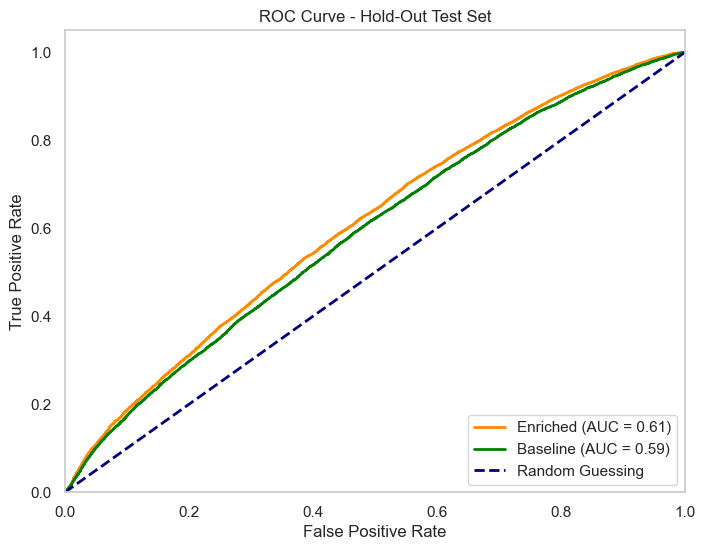

In [195]:
# Plot ROC Curves for Hold-Out Test Set
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
# Baseline and Enriched ROC Curves Plotted together for visual comparison

fpr_enriched, tpr_enriched, _ = roc_curve(y_test, proba_enriched)
roc_auc_enriched = auc(fpr_enriched, tpr_enriched)

fpr_baseline, tpr_baseline, _ = roc_curve(y_test, proba_baseline)
roc_auc_baseline = auc(fpr_baseline, tpr_baseline)

plt.plot(fpr_enriched, tpr_enriched, color='darkorange', lw=2, label=f'Enriched (AUC = {roc_auc_enriched:.2f})')
plt.plot(fpr_baseline, tpr_baseline, color='green', lw=2, label=f'Baseline (AUC = {roc_auc_baseline:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guessing')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Hold-Out Test Set')
plt.legend(loc="lower right")
plt.grid()
plt.show()

In [196]:
from sklearn.metrics import roc_curve
import numpy as np

# 1. Get the TPR, FPR, and all thresholds evaluated by scikit-learn
# (Let's do this for your Enriched Model as an example)
fpr, tpr, thresholds = roc_curve(y_test, proba_enriched)

# 2. Calculate Youden's J Statistic for every threshold row
# This math finds the point with the highest True Positives and lowest False Positives
j_scores = tpr - fpr

# 3. Find the index of the highest J score
best_idx = np.argmax(j_scores)

# 4. Extract the best threshold and its corresponding rates
optimal_threshold = thresholds[best_idx]
optimal_tpr = tpr[best_idx]
optimal_fpr = fpr[best_idx]

# Print your new optimization results!
print(f"Optimal Threshold: {optimal_threshold:.4f}")
print(f"True Positive Rate at this threshold: {optimal_tpr:.4f}")
print(f"False Positive Rate at this threshold: {optimal_fpr:.4f}")


Optimal Threshold: 0.4298
True Positive Rate at this threshold: 0.7018
False Positive Rate at this threshold: 0.5532


In [197]:
# Function that returns accuracy, precision, recall, F1 score, AUC-ROC score, and confusion matrix for a given a RandomForestClassifier model and dataset (scikit-learn, 2026)
def evaluate_model(model, X, y):
    # Predict on the dataset
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]

    # Calculate evaluation metrics
    accuracy = model.score(X, y)
    precision = precision_score(y, y_pred)
    recall = recall_score(y, y_pred)
    f1 = f1_score(y, y_pred)
    auc_roc = roc_auc_score(y, y_proba)
    cm = confusion_matrix(y, y_pred)

    # Print evaluation results
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"AUC-ROC Score: {auc_roc:.4f}")
    print("Confusion Matrix:")
    print(cm)

# Baseline confusion matrix and metrics
evaluate_model(random_search_baseline, X_test_baseline, y_test)

Accuracy: 0.5904
Precision: 0.4646
Recall: 0.5042
F1 Score: 0.4836
AUC-ROC Score: 0.5904
Confusion Matrix:
[[15773 10015]
 [ 8548  8692]]


In [198]:
# Enriched confusion matrix and metrics
evaluate_model(random_search_enriched, X_test_enriched, y_test)

Accuracy: 0.6069
Precision: 0.4816
Recall: 0.5031
F1 Score: 0.4921
AUC-ROC Score: 0.6069
Confusion Matrix:
[[16451  9337]
 [ 8566  8674]]


In [199]:
# 1. Grab the winning fitted pipeline from your randomized search variable
fitted_enriched_model = random_search_enriched.best_estimator_

# 2. Extract the feature names exactly as they exited the transformer step
feature_names = fitted_enriched_model.named_steps['column_transformer'].get_feature_names_out()

# 3. Extract the importances from the classifier step
importances = fitted_enriched_model.named_steps['classifier'].feature_importances_

# 4. Combine them into a clean DataFrame and sort by importance
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 5. Clean up the structural prefixes scikit-learn appends
importance_df['Feature'] = importance_df['Feature'].str.replace(r'^(remainder__|day_of_week__|neighborhood__)', '', regex=True)

# Print results
print(importance_df.to_string(index=False))



                   Feature  Importance
                     price    0.420253
              neighborhood    0.280664
capacity_weighted_distance    0.211815
                 lead_time    0.070685
      total_daily_capacity    0.006838
                is_weekend    0.006205
        global_event_count    0.003540


In [200]:
# Bootstrapping approach
np.random.seed(42)
n_iterations = 1000
bootstrapped_lifts = []

indices = np.arange(len(y_test))

for _ in range(n_iterations):
    # Resample row indices with replacement
    boot_idx = np.random.choice(indices, size=len(indices), replace=True)
    
    # Calculate AUCs on this bootstrap sample
    boot_baseline = roc_auc_score(y_test.iloc[boot_idx], proba_baseline[boot_idx])
    boot_enriched = roc_auc_score(y_test.iloc[boot_idx], proba_enriched[boot_idx])
    
    bootstrapped_lifts.append(boot_enriched - boot_baseline)

# Calculate 95% confidence interval
ci_lower = np.percentile(bootstrapped_lifts, 2.5)
ci_upper = np.percentile(bootstrapped_lifts, 97.5)

print("=== BOOTSTRAP RESAMPLING RESULTS ===")
print(f"95% Confidence Interval for Lift: [{ci_lower:.4f}, {ci_upper:.4f}]")
print(f"Is it significant (CI excludes 0)? {ci_lower > 0}")



=== BOOTSTRAP RESAMPLING RESULTS ===
95% Confidence Interval for Lift: [0.0143, 0.0189]
Is it significant (CI excludes 0)? True


https://towardsdatascience.com/confusion-matrix-made-simple-accuracy-precision-recall-f1-score/

https://towardsdatascience.com/roc-auc-explained-a-beginners-guide-to-evaluating-classification-models/
